## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [1]:
# 0.1 Importar pandas para leer los dataframes
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_rows", None)

In [2]:
# 0.2 Leer el dataframe
df_amz = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df_amz.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# Ver total columnas y filas del dataframe
df_amz.shape

(2443651, 9)

In [4]:
# Ver los tipos de cada columna del dataframe
df_amz.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [5]:
# 1.1 - Generate a frequency table for the product `category`.
values_per_category = df_amz["category"].value_counts()
proportion_table = df_amz["category"].value_counts(normalize=True)
values_per_category, proportion_table

(category
 Sports & Outdoors                                   836265
 Beauty                                               19312
 Handmade Clothing, Shoes & Accessories               19229
 Bath & Body                                          19092
 Birthday Gifts                                       18978
 Manicure & Pedicure Products                         18940
 Skin Care                                            18769
 Make-up                                              18756
 Hair Care                                            18735
 Fragrances                                           18564
 Handmade Gifts                                       18295
 Handmade Home Décor                                  18146
 Luggage and travel gear                              18142
 Handmade Jewellery                                   18044
 Handmade Artwork                                     17878
 Women                                                17772
 Handmade Home & Kitchen Produ

In [6]:
# Create a new df with categories counts
category_count = pd.crosstab(index = df_amz["category"],  # Make a crosstab
                             columns="count")      # Name the count column
category_count.sort_values(by="count", ascending=False)

col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
Manicure & Pedicure Products,18940
Skin Care,18769
Make-up,18756
Hair Care,18735


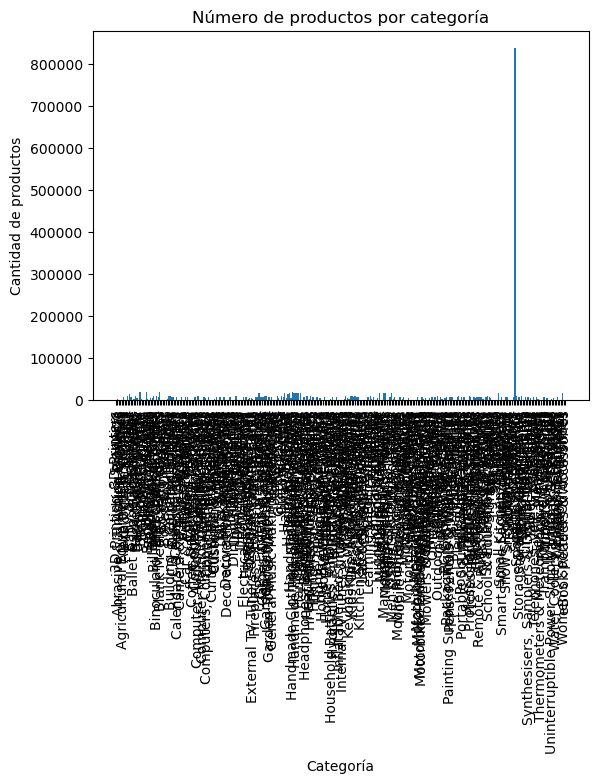

In [7]:
# Create the bar plot
plt.bar(category_count.index, category_count['count'])

# Etiquetas y título
plt.xlabel('Categoría')
plt.ylabel('Cantidad de productos')
plt.title('Número de productos por categoría')

# Mostrar el gráfico
plt.xticks(rotation=90)  # Rotar las etiquetas si es necesario
plt.show()

/opt/anaconda3/envs/ironhack_labs/lib/python3.12/site-packages/numpy/core/fromnumeric.py:59: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


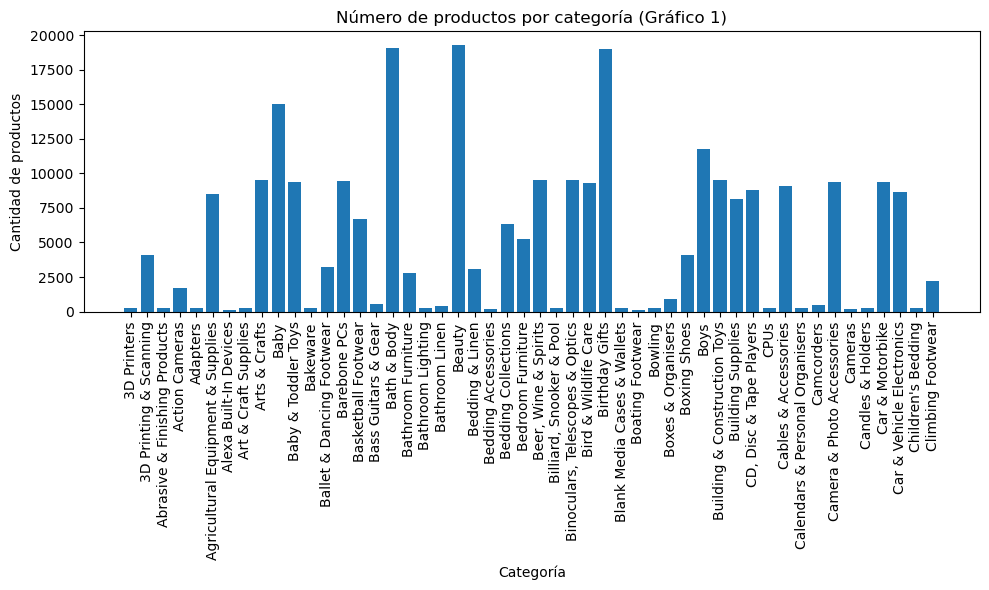

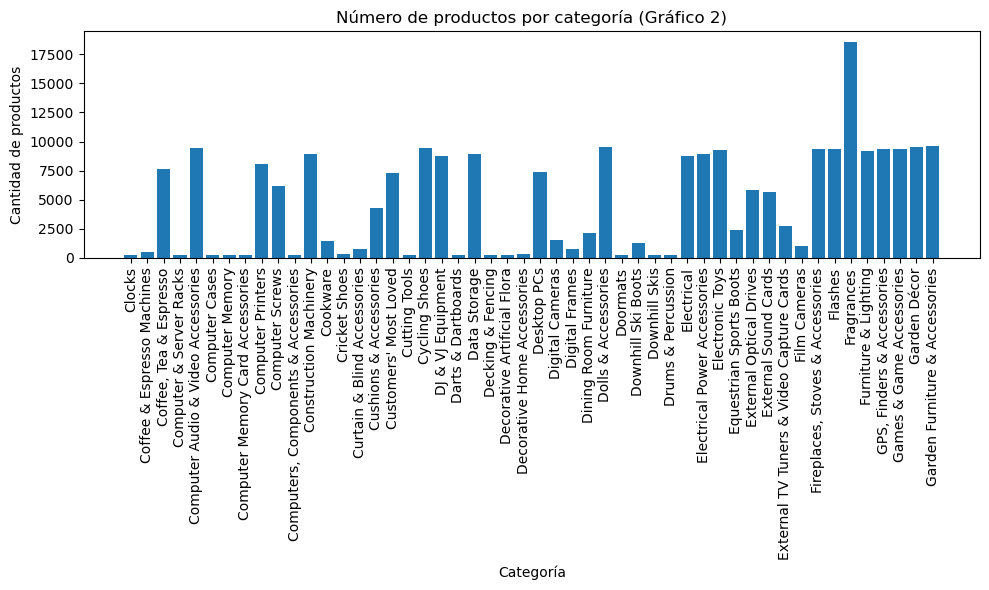

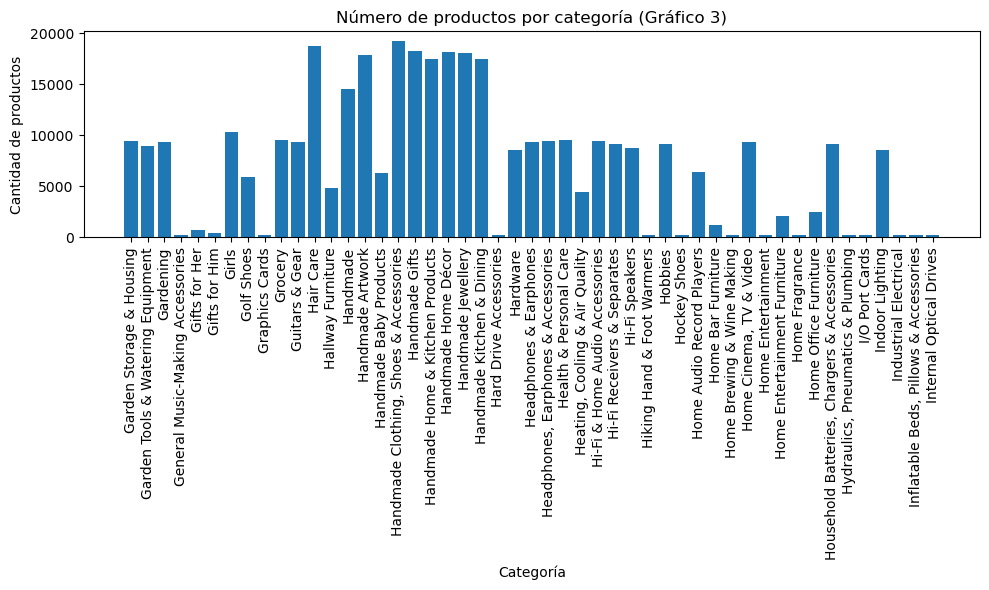

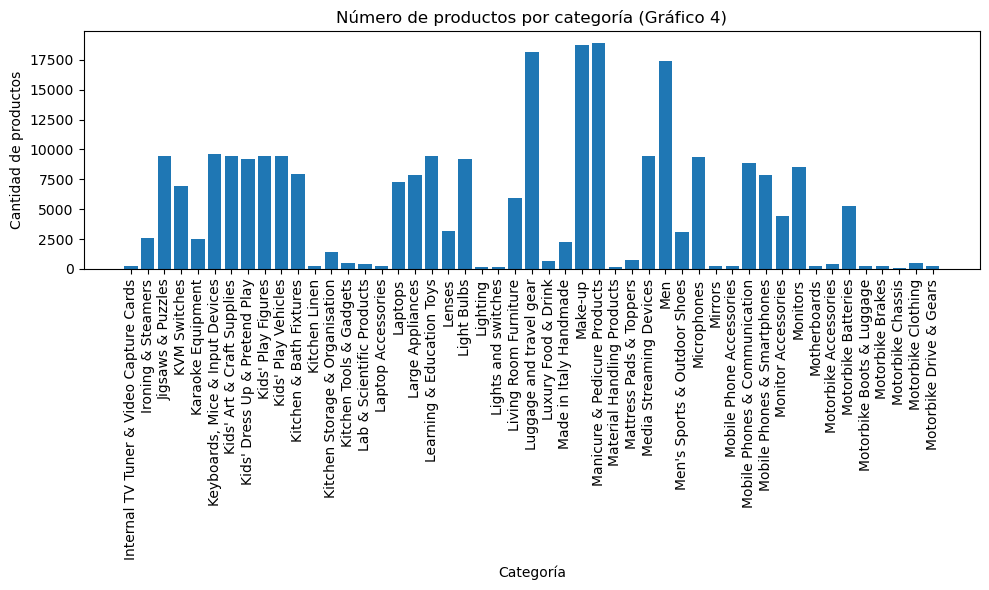

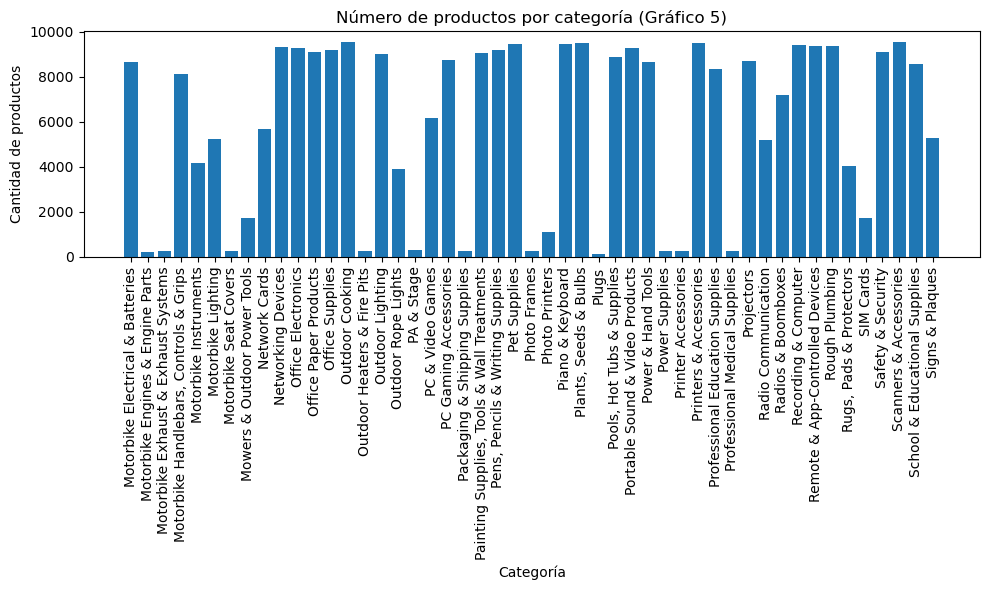

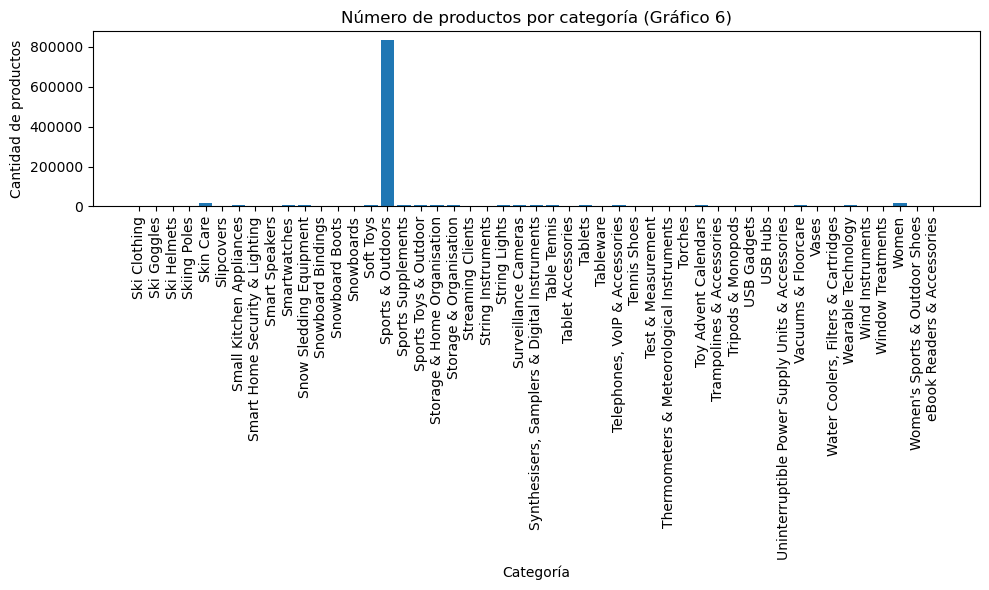

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Supongamos que este es tu DataFrame con 296 filas
# category_count = DataFrame con columnas ['category', 'count']

# Paso 1: Dividimos el DataFrame en 6 partes
df_split = np.array_split(category_count, 6)

# Paso 2: Crear los barplots para cada subconjunto
for i, subset in enumerate(df_split):
    plt.figure(figsize=(10, 6))  # Tamaño del gráfico
    plt.bar(subset.index, subset['count'])
    
    # Etiquetas y título
    plt.xlabel('Categoría')
    plt.ylabel('Cantidad de productos')
    plt.title(f'Número de productos por categoría (Gráfico {i+1})')
    
    # Ajustar las etiquetas del eje X
    plt.xticks(rotation=90)  # Rotar las etiquetas si es necesario
    plt.tight_layout()  # Asegurar que el gráfico no se superponga
    
    # Mostrar el gráfico
    plt.show()


In [9]:
# 1.2 - Which are the top 5 most listed product categories?
top5_most_listed_categories = category_count.sort_values(by="count", ascending=False).head(5)
top5_most_listed_categories

col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


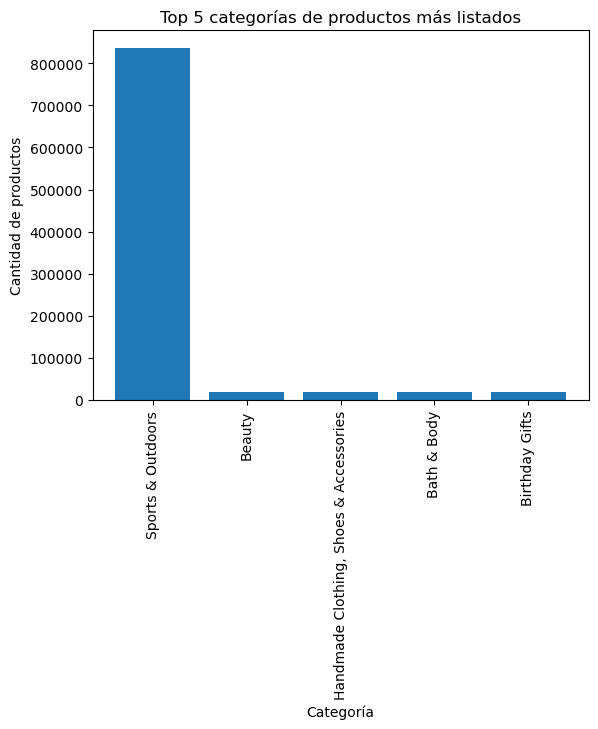

In [10]:
# Create the bar plot
plt.bar(top5_most_listed_categories.index, top5_most_listed_categories['count'])

# Etiquetas y título
plt.xlabel('Categoría')
plt.ylabel('Cantidad de productos')
plt.title('Top 5 categorías de productos más listados')

# Mostrar el gráfico
plt.xticks(rotation=90)  # Rotar las etiquetas si es necesario
plt.show()

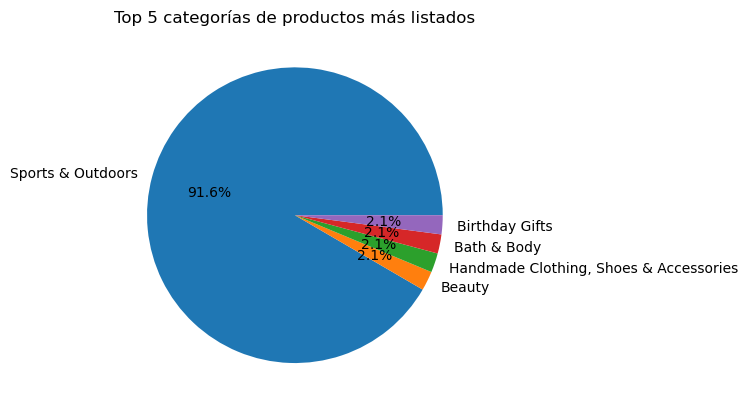

In [11]:
# Crear el gráfico de tarta
plt.pie(top5_most_listed_categories['count'], 
        labels=top5_most_listed_categories.index, 
        autopct='%1.1f%%',  # Mostrar porcentajes en el gráfico
        startangle=0)  # Empezar el gráfico desde un ángulo de 90 grados

# Título
plt.title('Top 5 categorías de productos más listados')

# Mostrar el gráfico
plt.show()


### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [29]:
# 1/ Measures of Centrality
# Describe prices
df_amz.price.describe().round(2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [30]:
# 1.1 / Calculate the mean, median, and mode for price products
mean_prices_amz = df_amz["price"].mean()
median_prices_amz = df_amz["price"].median()
mode_prices_amz = df_amz['price'].mode()[0]

print(f"Products Amazon UK, \n Mean:{mean_prices_amz} \n Median:{median_prices_amz} \n Mode:{mode_prices_amz}.")

Products Amazon UK, 
 Mean:89.24380943923663 
 Median:19.09 
 Mode:9.99.


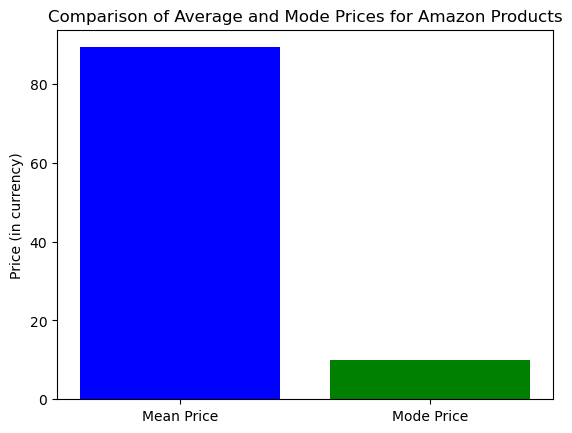

In [31]:
# 1.2 / What's the average price point of products listed? How does this compare with the most common price point (mode)?

import matplotlib.pyplot as plt

# Valores a graficar
values = [mean_prices_amz, mode_prices_amz]
labels = ['Mean Price', 'Mode Price']

# Crear el gráfico de barras
plt.bar(labels, values, color=['blue', 'green'])

# Etiquetas y título
plt.ylabel('Price (in currency)')
plt.title('Comparison of Average and Mode Prices for Amazon Products')

# Mostrar el gráfico
plt.show()


In [32]:
# 2 / Measures of Dispersion
# 2.1 / Determine the variance, standard deviation, range, and interquartile range for product `price`.
variance_prices_amz = df_amz["price"].var() # Variance
stdev_prices_amz = df_amz["price"].std() # Standard deviation
range_prices_amz = df_amz['price'].max() - df_amz['price'].min() # Range

# Interquartile range for price
iqr_prices_amz = df_amz["price"].quantile(0.75) - df_amz["price"].quantile(0.25)

print(f"Products Amazon UK Measures of Dispersion \n Variance: {variance_prices_amz} \n Standard deviation;: {stdev_prices_amz} \n Range: {range_prices_amz} \n Interquartile range: {iqr_prices_amz}")

Products Amazon UK Measures of Dispersion 
 Variance: 119445.4853225653 
 Standard deviation;: 345.6088617535223 
 Range: 100000.0 
 Interquartile range: 36.0


Estos resultados indican una variabilidad significativa en los precios de los productos. La alta desviación estándar y el rango de 100,000 sugieren la presencia de algunos productos con precios extremadamente altos o bajos, lo que podría estar generando este amplio rango y elevada dispersión.

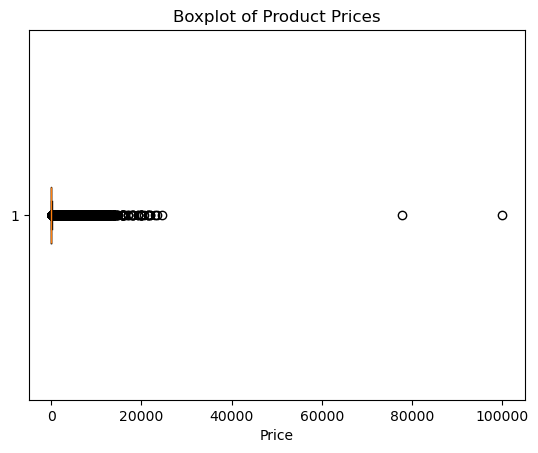

In [33]:
import matplotlib.pyplot as plt

plt.boxplot(df_amz['price'], vert=False)
plt.title('Boxplot of Product Prices')
plt.xlabel('Price')
plt.show()


Aquí podemos ver la dispersión de precios en un boxplot, teniendo productos con precios muy altos (podrían ser outliers) respecto al grueso de productos que se sitúan en precios más bien bajos.

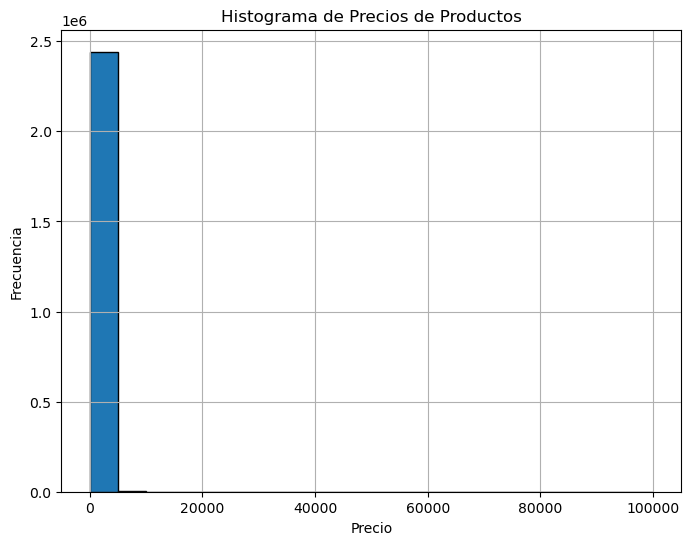

In [34]:
# 3 / Visualizations:
# 3.1 / Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. 
# *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
# Generate histogram
import matplotlib.pyplot as plt

# Generar el histograma para visualizar la distribución de precios
plt.figure(figsize=(8, 6))
plt.hist(df_amz['price'], bins=20, edgecolor='black')
plt.title('Histograma de Precios de Productos')
plt.xlabel('Precio')
plt.ylabel('Frecuencia')
plt.grid(True)

plt.show()


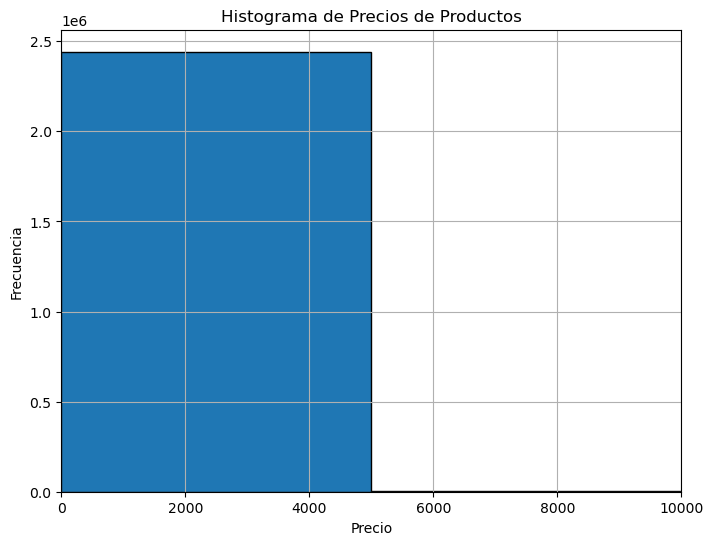

In [35]:
# Create a histogram with most common prices products
import matplotlib.pyplot as plt

# Generar el histograma para visualizar la distribución de precios
plt.figure(figsize=(8, 6))
plt.hist(df_amz['price'], bins=20, edgecolor='black')
plt.title('Histograma de Precios de Productos')
plt.xlabel('Precio')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.xlim(0, 10000)
plt.show()

Podemos observar que la mayoría de productos se sitúan entre 0 y 5000. Para ello hemos tenido que acotar el histograma en un rango de precios de 0 a 10.000.

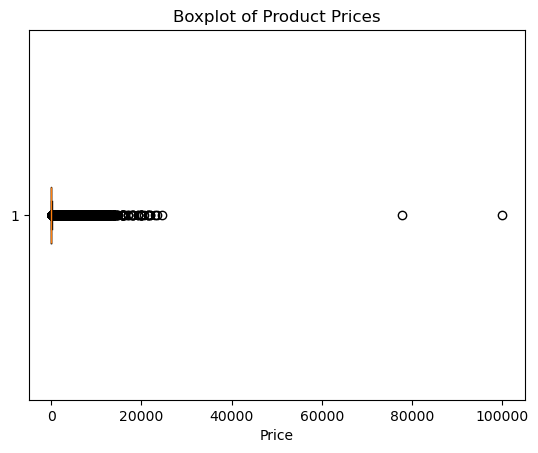

In [36]:
# 3.2 / Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 
# Create the boxplot to show possible outliers
import matplotlib.pyplot as plt

plt.boxplot(df_amz['price'], vert=False)
plt.title('Boxplot of Product Prices')
plt.xlabel('Price')
plt.show()

In [37]:
# Podemos apreciar que hay dos outliers 
outliers = df_amz[df_amz['price'] > 40000]
outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
1987238,2235317,B0CDVKNBRV,Générique L.A 350° - I5 11400F - RTX 3050 8G -...,0.0,0,77752.0,False,0,Desktop PCs
2008013,2259336,B091F5Y3CT,HB FBA Test Treadmill,0.0,0,100000.0,False,0,Sports & Outdoors


### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [21]:
# 1. Measures of Centrality:
# 1.1 Calculate the mean, median, and mode for the `rating` of products.
df_amz["stars"]

0          4.7
1          4.7
2          4.7
3          4.7
4          4.6
5          4.7
6          4.7
7          4.7
8          4.7
9          4.5
10         4.8
11         4.6
12         4.6
13         4.5
14         4.7
15         4.6
16         4.6
17         4.6
18         4.5
19         4.5
20         4.6
21         4.8
22         4.7
23         4.7
24         4.5
25         0.0
26         4.5
27         4.7
28         4.8
29         4.7
30         4.4
31         4.4
32         4.4
33         4.3
34         4.8
35         4.8
36         4.6
37         4.7
38         4.7
39         4.8
40         4.5
41         4.7
42         4.7
43         4.6
44         4.7
45         4.6
46         4.7
47         4.5
48         4.5
49         4.1
50         4.6
51         4.7
52         4.9
53         4.7
54         4.5
55         4.4
56         4.7
57         4.7
58         4.8
59         4.5
60         4.7
61         4.7
62         4.7
63         4.8
64         4.8
65         4.7
66        

In [22]:
df_amz["stars"].describe().round(2)

count    2443651.00
mean           2.15
std            2.19
min            0.00
25%            0.00
50%            0.00
75%            4.40
max            5.00
Name: stars, dtype: float64

Podemos ver que hay productos con 0 estrellas, esto significa que no han sido valorados ya que Amazon te permite valorar como mínimo con 1 estrella.
Así que vamos a filtrar por los productos que tengan más de 0 estrellas.

In [24]:
# Eliminar las filas con 'stars' igual a 0 o NaN
df_rating_filtered = df_amz[(df_amz['stars'] != 0.0) & (df_amz['stars'].notna())]


In [27]:
df_rating_filtered.stars.describe().round(2)

count    1218010.00
mean           4.32
std            0.56
min            1.00
25%            4.10
50%            4.40
75%            4.60
max            5.00
Name: stars, dtype: float64

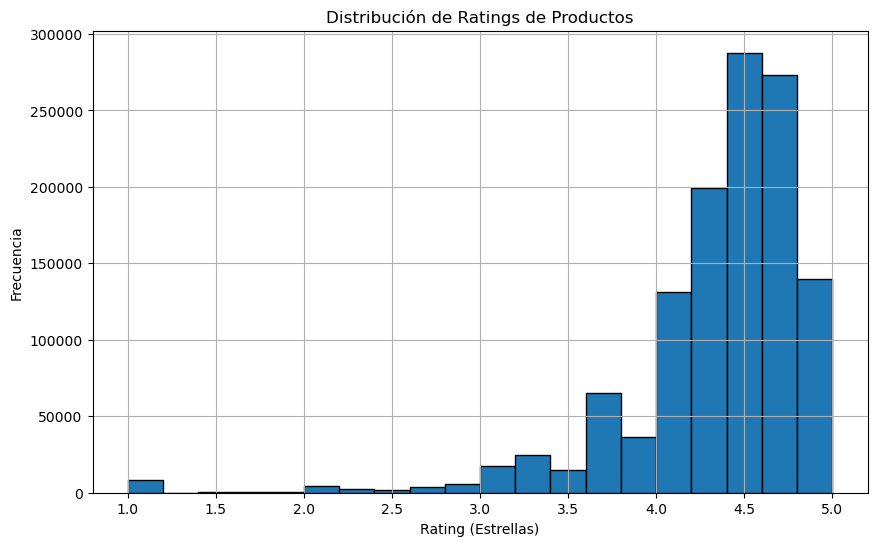

In [28]:
# 1.2 How do customers generally rate products? Is there a common trend?
# Visualizar la distribución de los ratings con un histograma
plt.figure(figsize=(10, 6))
plt.hist(df_rating_filtered['stars'], bins=20, edgecolor='black')
plt.title('Distribución de Ratings de Productos')
plt.xlabel('Rating (Estrellas)')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.show()

Podemos observar una tendencia positiva en la puntuación de productos, destacando 4.5 como mayor valor de puntuación.

In [42]:
# 2 / Measures of Dispersion**:
# 2.1 / Determine the variance, standard deviation, and interquartile range for product `rating`.
variance_rating_amz = df_rating_filtered["stars"].var() # Variance
stdev_rating_amz = df_rating_filtered["stars"].std() # Standard deviation
range_rating_amz = df_rating_filtered["stars"].max() - df_amz["stars"].min() # Range

# Interquartile range for rating
iqr_rating_amz = df_rating_filtered["stars"].quantile(0.75) - df_rating_filtered["stars"].quantile(0.25)

print(f"Products Amazon UK Measures of Dispersion \n Variance: {variance_rating_amz} \n Standard deviation;: {stdev_rating_amz} \n Range: {range_rating_amz} \n Interquartile range: {iqr_rating_amz}")

Products Amazon UK Measures of Dispersion 
 Variance: 0.30834337523805183 
 Standard deviation;: 0.5552867504614637 
 Range: 5.0 
 Interquartile range: 0.5


Podemos observar que la varianza es muy baja, por lo que las calificaciones no están muy dispersas.
La desviación estandar también es baja por lo que nos indica que la mayoría de valores no están muy alejados del valor promedio.
El rango es amplio y lo sabemos ya que ocupa todo el espectro de 1 a 5 estrellas.
Y el iqr es bajo por lo que indica que el 50% de las calificaciones centrales están muy cercanas entre sí.

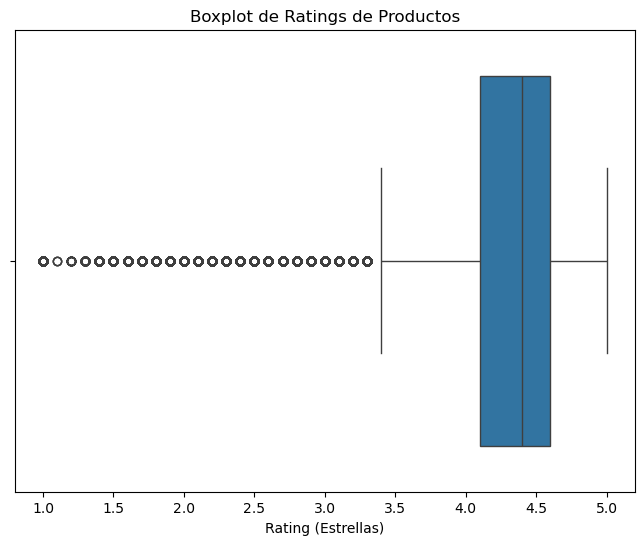

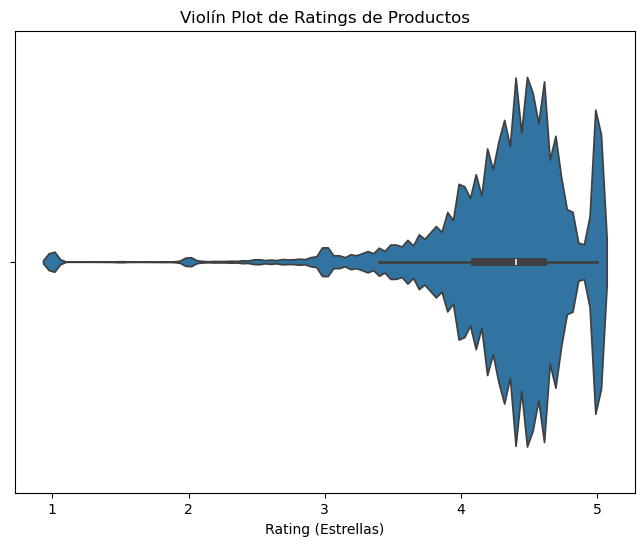

In [49]:
# 2.2 / Are the ratings consistent, or is there a wide variation in customer feedback?

import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot de las calificaciones
plt.figure(figsize=(8, 6))
sns.boxplot(x=df_rating_filtered['stars'])
plt.title('Boxplot de Ratings de Productos')
plt.xlabel('Rating (Estrellas)')
plt.show()

# Crear el violín plot para visualizar la distribución de las calificaciones
plt.figure(figsize=(8, 6))
sns.violinplot(x=df_rating_filtered['stars'])
plt.title('Violín Plot de Ratings de Productos')
plt.xlabel('Rating (Estrellas)')
plt.show()


Con las conclusiones anteriores y tras visualizar estas nuevas gráficas podemos observar que la mayoría de calificaciones se encuentran entre 4 y 4.5 estrellas.

In [51]:
# 3 / Shape of the Distribution:
# 3.1 / Calculate the skewness and kurtosis for the `rating` column. 
from scipy.stats import skew, kurtosis

# Calcular la asimetría (skewness) y la curtosis para la columna 'stars'
rating_skewness = skew(df_rating_filtered['stars'])
rating_kurtosis = kurtosis(df_rating_filtered['stars'])

rating_skewness, rating_kurtosis

(-2.3795651817332506, 9.781892609238655)

In [ ]:
# 3.2 / Are the ratings normally distributed, or do they lean towards higher or lower values?

Aquí podemos observar que el sesgo además de ser negativo es alto, por lo que la mayoría de valores se establecen a la derecha como veíamos anteriormente y hay una cola de valores bajos que distorsionan la forma de la distribución.
Además la curtosis es bastante alta, esto muestra que la distribución tiene colas más largas y más valores extremos (outliers) que una distribución normal.

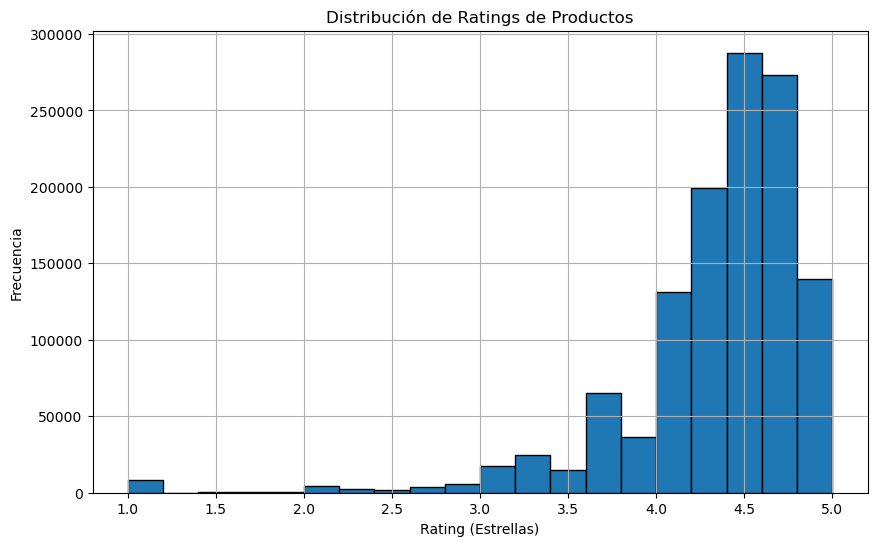

In [52]:
# 4 / Visualizations:
# 4.1 Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
# Visualizar la distribución de los ratings con un histograma
plt.figure(figsize=(10, 6))
plt.hist(df_rating_filtered['stars'], bins=20, edgecolor='black')
plt.title('Distribución de Ratings de Productos')
plt.xlabel('Rating (Estrellas)')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.show()

Con este histograma podemos ver claramente que el rating más común es 4.5 estrellas.